In [1]:
import pandas as pd

path = "/kaggle/input/datasets/ivoalmeidaramoa/igov-csv/Dataset-iGov.csv"

try:
    df = pd.read_csv(path)
except UnicodeDecodeError:
    df = pd.read_csv(path, encoding="latin1")
except pd.errors.ParserError:
    df = pd.read_csv(path, sep=";")

df.head()
df.shape, df.columns.tolist()
df.info()
df.describe(include="all").T


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_registo              200 non-null    int64  
 1   data_registo            200 non-null    object 
 2   unidade_organizacional  200 non-null    object 
 3   tipo_servico            200 non-null    object 
 4   indicador_si            200 non-null    float64
 5   taxa_resolucao          200 non-null    float64
 6   tempo_resposta          200 non-null    int64  
 7   satisfacao_cidadao      200 non-null    float64
 8   volume_interacoes       200 non-null    int64  
 9   canal_utilizado         200 non-null    object 
 10  taxa_abandono           200 non-null    float64
 11  erros_tecnicos          200 non-null    int64  
 12  transparencia           200 non-null    object 
 13  feedback_cidadao        200 non-null    object 
 14  segmentacao_utilizador  200 non-null    ob

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_registo,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
data_registo,200,152,2024-08-18,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unidade_organizacional,200,8,Serviços De Educação,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_servico,200,7,Portal Online,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
indicador_si,200.0,NaN,NaN,NaN,81.58325,12.373367,60.43,71.3925,82.39,92.5575,99.99
taxa_resolucao,200.0,NaN,NaN,NaN,82.90985,7.76995,70.41,75.84,82.275,88.7925,97.72
tempo_resposta,200.0,NaN,NaN,NaN,58.73,33.991088,1.0,29.75,54.5,88.25,118.0
satisfacao_cidadao,200.0,NaN,NaN,NaN,3.9855,0.591089,3.0,3.5,4.0,4.5,5.0
volume_interacoes,200.0,NaN,NaN,NaN,251.59,142.126781,12.0,131.25,251.0,366.5,499.0
canal_utilizado,200,6,Presencial,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
#Preparação mínima
import pandas as pd
import numpy as np

df["data_registo"] = pd.to_datetime(df["data_registo"], errors="coerce")  # já está YYYY-MM-DD
df["ano"] = df["data_registo"].dt.year
df["mes"] = df["data_registo"].dt.month

num_cols = df.select_dtypes(include="number").columns.tolist()
num_cols = [c for c in num_cols if c not in ["id_registo", "ano", "mes"]]

cat_cols = df.select_dtypes(include="object").columns.tolist()

num_cols, cat_cols


(['indicador_si',
  'taxa_resolucao',
  'tempo_resposta',
  'satisfacao_cidadao',
  'volume_interacoes',
  'taxa_abandono',
  'erros_tecnicos',
  'indicador_kpi'],
 ['unidade_organizacional',
  'tipo_servico',
  'canal_utilizado',
  'transparencia',
  'feedback_cidadao',
  'segmentacao_utilizador',
  'area_tematica'])

In [3]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
indicador_si,200.0,81.58325,12.373367,60.43,71.3925,82.390,92.5575,99.99
taxa_resolucao,200.0,82.90985,7.769950,70.41,75.8400,82.275,88.7925,97.72
tempo_resposta,200.0,58.73000,33.991088,1.00,29.7500,54.500,88.2500,118.00
satisfacao_cidadao,200.0,3.98550,0.591089,3.00,3.5000,4.000,4.5000,5.00
volume_interacoes,200.0,251.59000,142.126781,12.00,131.2500,251.000,366.5000,499.00
taxa_abandono,200.0,12.55550,6.568370,0.23,7.8975,13.325,16.5950,24.83
erros_tecnicos,200.0,7.03500,4.176240,0.00,3.0000,7.000,11.0000,14.00
indicador_kpi,200.0,75.16680,14.210823,50.11,63.0750,75.475,87.6100,99.99


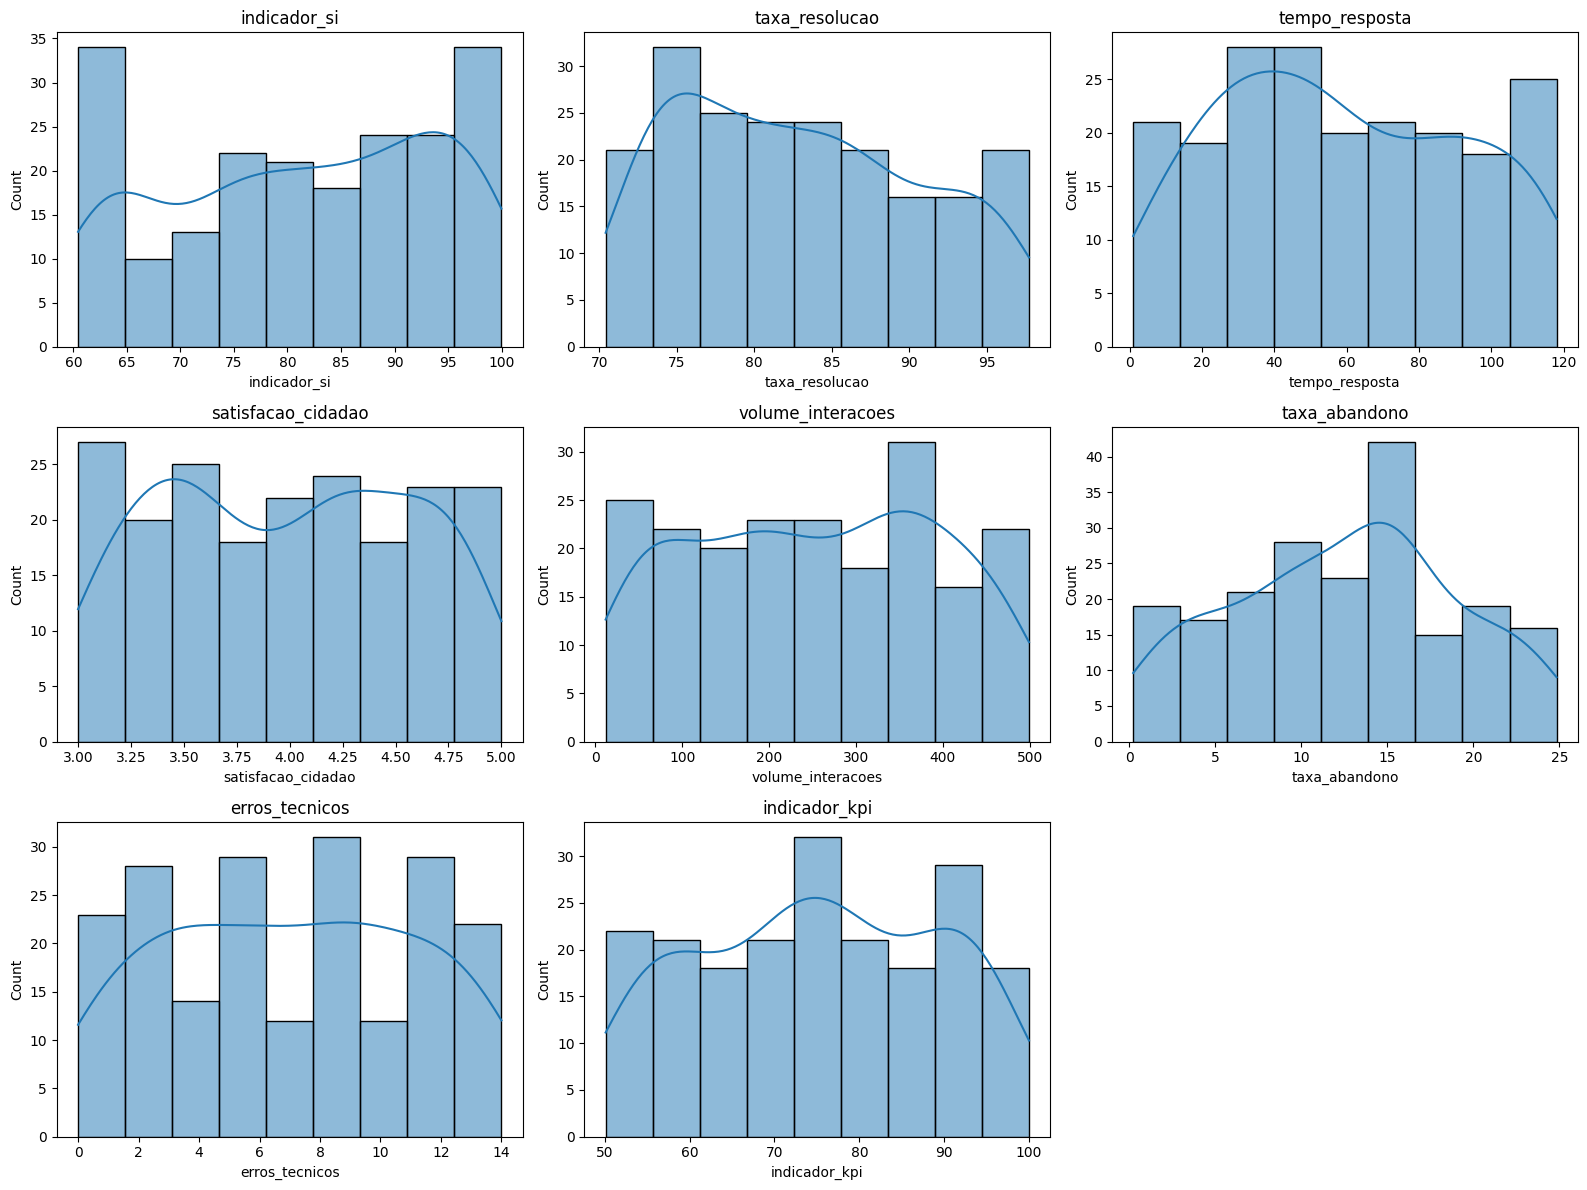

In [4]:
#Histogramas
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

n = len(num_cols)
cols = 3
rows = int(np.ceil(n / cols))

plt.figure(figsize=(16, 4*rows))
for i, c in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(df[c].dropna(), kde=True)
    plt.title(c)

plt.tight_layout()
plt.show()


In [5]:
#Estatísticas
def stats_table(df, cols):
    out = []
    for c in cols:
        s = df[c].dropna()
        m = s.mode()
        out.append({
            "variavel": c,
            "n": int(s.count()),
            "min": float(s.min()),
            "q1": float(s.quantile(0.25)),
            "mediana": float(s.median()),
            "media": float(s.mean()),
            "q3": float(s.quantile(0.75)),
            "max": float(s.max()),
            "moda": float(m.iloc[0]) if len(m) else np.nan,
            "desvio_padrao": float(s.std(ddof=1)),
        })
    return pd.DataFrame(out).set_index("variavel")

stats = stats_table(df, num_cols)
stats


,n,min,q1,mediana,media,q3,max,moda,desvio_padrao
variavel,,,,,,,,,
indicador_si,200,60.43,71.3925,82.390,81.58325,92.5575,99.99,63.65,12.373367
taxa_resolucao,200,70.41,75.8400,82.275,82.90985,88.7925,97.72,76.79,7.769950
tempo_resposta,200,1.00,29.7500,54.500,58.73000,88.2500,118.00,29.00,33.991088
satisfacao_cidadao,200,3.00,3.5000,4.000,3.98550,4.5000,5.00,3.50,0.591089
volume_interacoes,200,12.00,131.2500,251.000,251.59000,366.5000,499.00,49.00,142.126781
taxa_abandono,200,0.23,7.8975,13.325,12.55550,16.5950,24.83,8.98,6.568370
erros_tecnicos,200,0.00,3.0000,7.000,7.03500,11.0000,14.00,9.00,4.176240
indicador_kpi,200,50.11,63.0750,75.475,75.16680,87.6100,99.99,52.24,14.210823


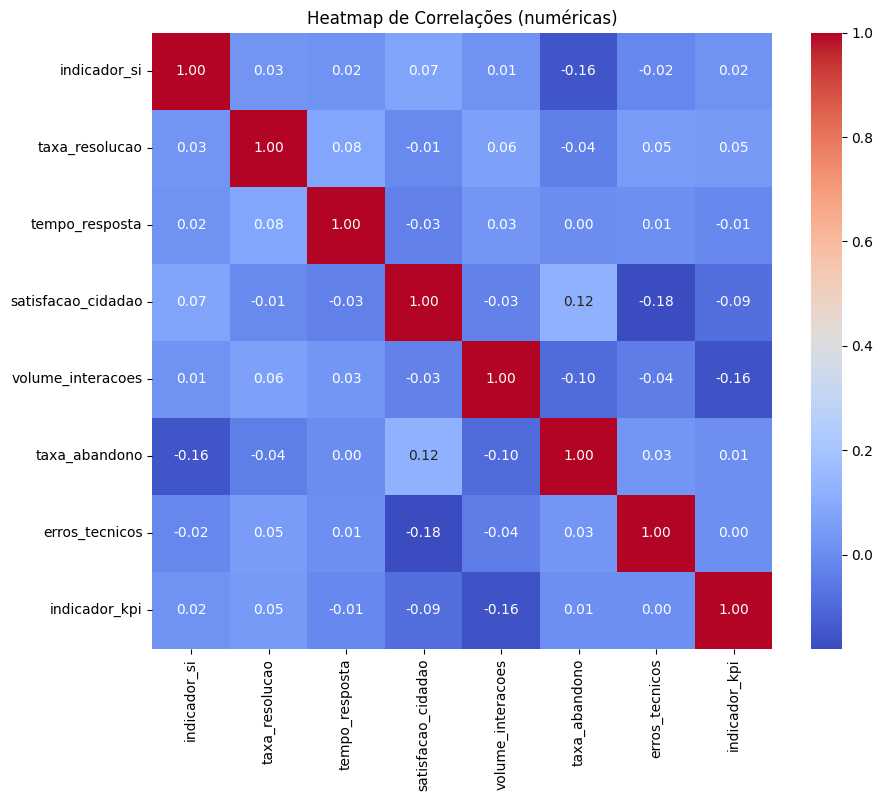

In [6]:
#HeatMap
corr = df[num_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Heatmap de Correlações (numéricas)")
plt.show()


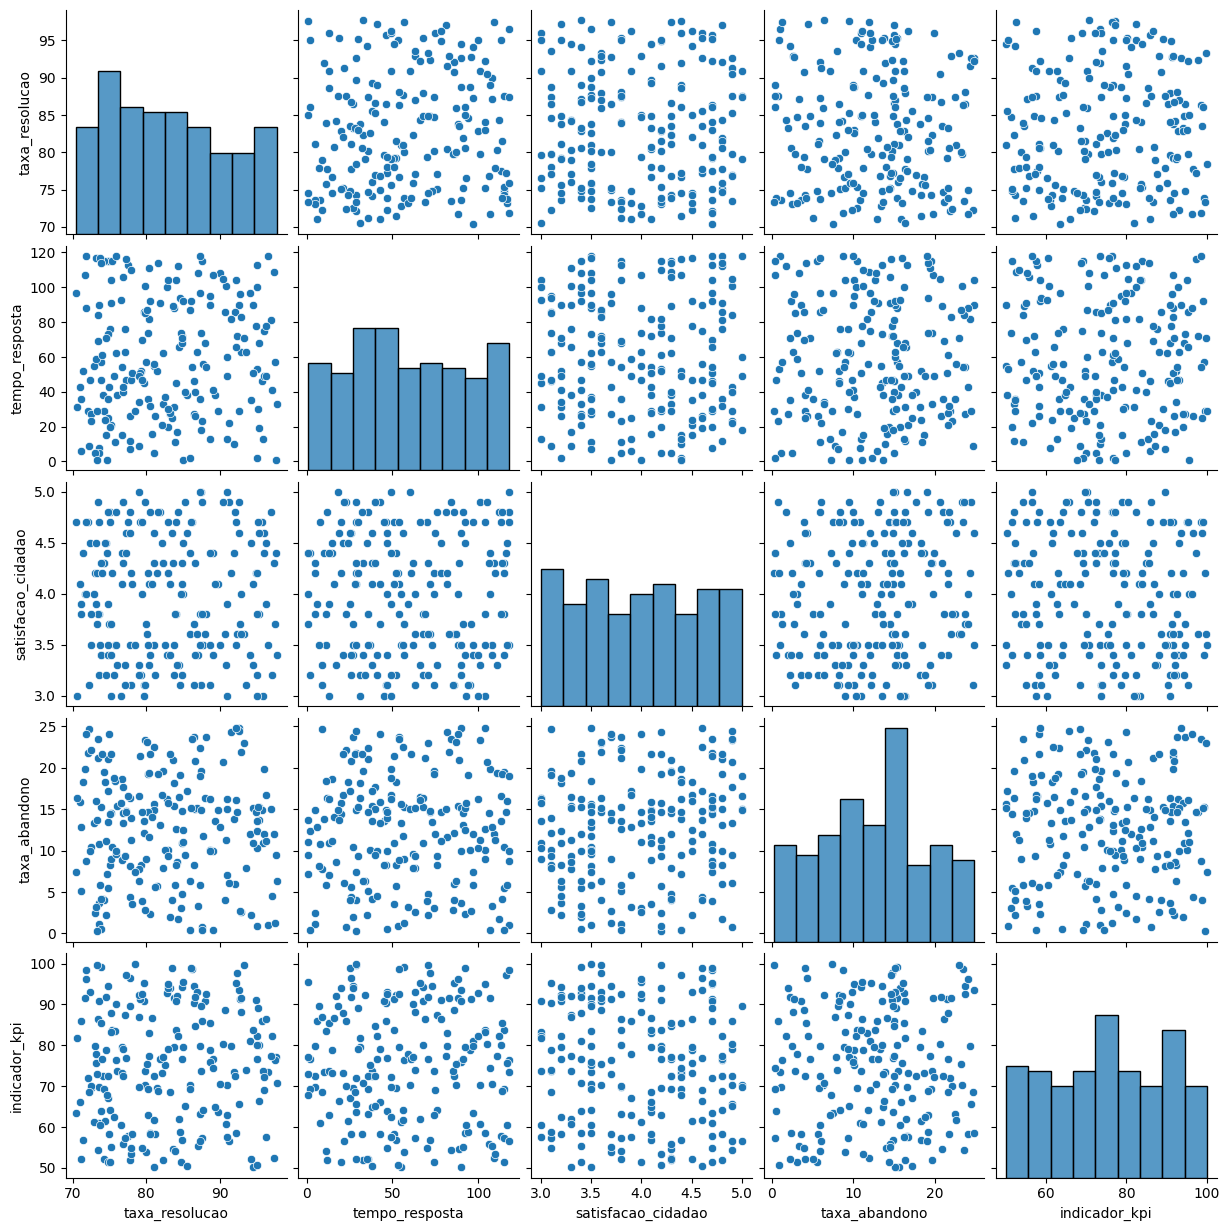

In [7]:
#Scatterplot Matrix
pair_cols = [c for c in ["taxa_resolucao","tempo_resposta","satisfacao_cidadao","taxa_abandono","indicador_kpi"] if c in df.columns]
sns.pairplot(df[pair_cols].dropna())
plt.show()


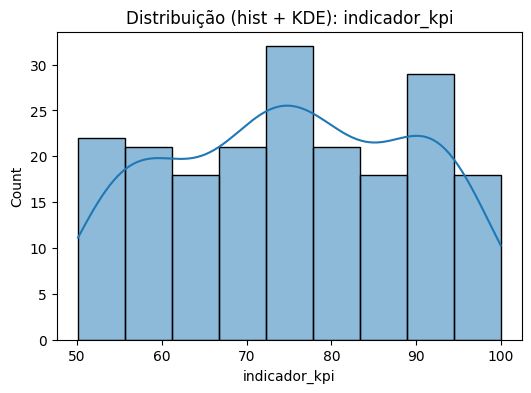

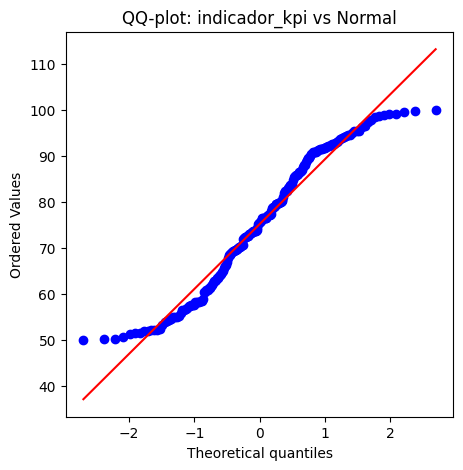

ShapiroResult(statistic=np.float64(0.9529401634534156), pvalue=np.float64(5.7934628694992704e-05))

In [8]:
#Normalidade (hist + QQ-plot + Shapiro)

from scipy import stats as spstats

x = df["indicador_kpi"].dropna()

plt.figure(figsize=(6,4))
sns.histplot(x, kde=True)
plt.title("Distribuição (hist + KDE): indicador_kpi")
plt.show()

plt.figure(figsize=(5,5))
spstats.probplot(x, dist="norm", plot=plt)
plt.title("QQ-plot: indicador_kpi vs Normal")
plt.show()

x_test = x.sample(150, random_state=42) if len(x) > 150 else x
spstats.shapiro(x_test)


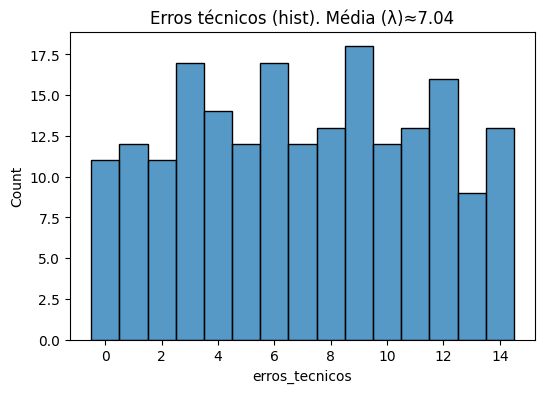

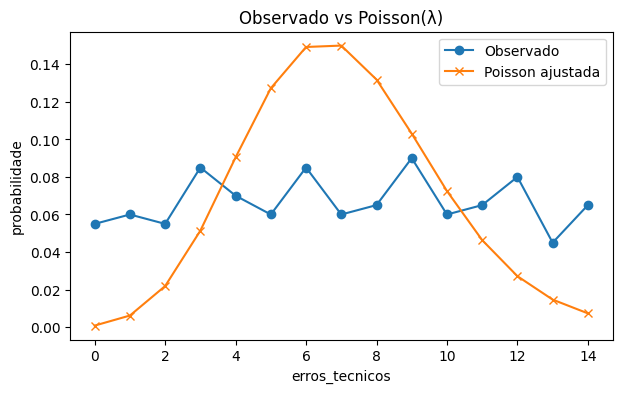

In [9]:
#Poisson

from scipy import stats as spstats

x = df["erros_tecnicos"].dropna()
lam = x.mean()

plt.figure(figsize=(6,4))
sns.histplot(x, discrete=True)
plt.title(f"Erros técnicos (hist). Média (λ)≈{lam:.2f}")
plt.show()

values = np.arange(int(x.min()), int(x.max()) + 1)
pmf = spstats.poisson.pmf(values, mu=lam)
pmf = pmf / pmf.sum()

obs = x.value_counts().sort_index()
obs = obs.reindex(values, fill_value=0) / len(x)

plt.figure(figsize=(7,4))
plt.plot(values, obs.values, marker="o", label="Observado")
plt.plot(values, pmf, marker="x", label="Poisson ajustada")
plt.title("Observado vs Poisson(λ)")
plt.xlabel("erros_tecnicos")
plt.ylabel("probabilidade")
plt.legend()
plt.show()


In [10]:
#Binomial
threshold = 85
success = (df["taxa_resolucao"] >= threshold).astype(int)

success.value_counts(), success.mean()


(taxa_resolucao
 0    124
 1     76
 Name: count, dtype: int64,
 np.float64(0.38))

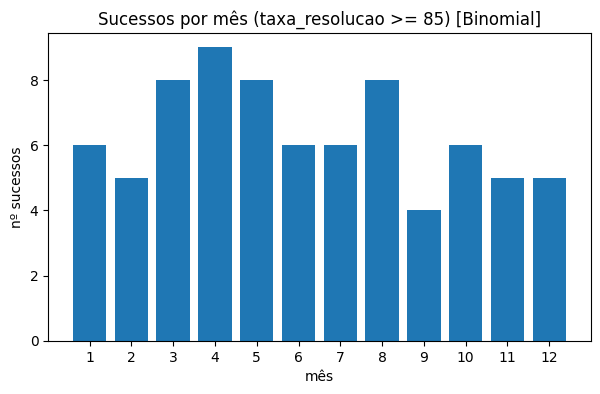

In [11]:
by_month_success = df.groupby("mes")["taxa_resolucao"].apply(lambda s: (s >= threshold).sum())

plt.figure(figsize=(7,4))
plt.bar(by_month_success.index.astype(str), by_month_success.values)
plt.title(f"Sucessos por mês (taxa_resolucao >= {threshold}) [Binomial]")
plt.xlabel("mês")
plt.ylabel("nº sucessos")
plt.show()


In [12]:
#t-Student
from scipy import stats as spstats

x = df["indicador_kpi"].dropna()
n = len(x)
mean = x.mean()
std = x.std(ddof=1)
alpha = 0.05

tcrit = spstats.t.ppf(1 - alpha/2, df=n-1)
margin = tcrit * std / np.sqrt(n)

(mean, mean - margin, mean + margin)



(np.float64(75.16680000000001),
 np.float64(73.18526573549076),
 np.float64(77.14833426450926))

In [13]:
#Clustering

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

X = df[num_cols].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scores = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels = km.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

scores


{2: np.float64(0.09961321704946918),
 3: np.float64(0.08995196869934531),
 4: np.float64(0.09485754370823214),
 5: np.float64(0.09444971983285352),
 6: np.float64(0.10858678852013869),
 7: np.float64(0.09818553943923196),
 8: np.float64(0.09995004778948069),
 9: np.float64(0.09053952082327328),
 10: np.float64(0.09634428417037441)}

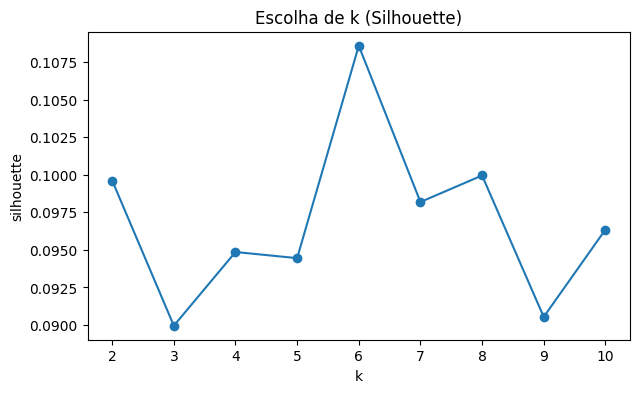

6

In [14]:
plt.figure(figsize=(7,4))
plt.plot(list(scores.keys()), list(scores.values()), marker="o")
plt.title("Escolha de k (Silhouette)")
plt.xlabel("k")
plt.ylabel("silhouette")
plt.show()

best_k = max(scores, key=scores.get)
best_k


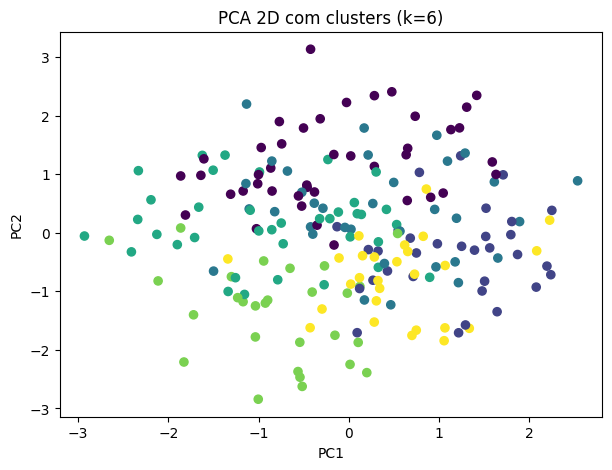

In [15]:
km = KMeans(n_clusters=best_k, random_state=42, n_init="auto")
labels = km.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X2 = pca.fit_transform(X_scaled)

plt.figure(figsize=(7,5))
plt.scatter(X2[:,0], X2[:,1], c=labels, s=35)
plt.title(f"PCA 2D com clusters (k={best_k})")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


In [16]:
import plotly.io as pio
pio.renderers.default = "iframe"
pio.renderers.default


'iframe'

In [17]:
#Dashboard
import numpy as np
import pandas as pd

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Render (no Kaggle, o iframe costuma ser o mais fiável)
pio.renderers.default = "iframe"

# --- Garantir colunas base ---
df["data_registo"] = pd.to_datetime(df["data_registo"], errors="coerce")
df["ano"] = df["data_registo"].dt.year
df["mes"] = df["data_registo"].dt.month

# Se num_cols não existir, cria aqui (exclui ID e derivados de data)
try:
    _ = num_cols
except NameError:
    num_cols = df.select_dtypes(include="number").columns.tolist()
    num_cols = [c for c in num_cols if c not in ["id_registo", "ano", "mes"]]

# --- Clustering global (para ficar no dashboard) ---
X = df[num_cols].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# escolher k por silhouette (intervalo pequeno para ser rápido)
scores = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels_k = km.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels_k)
best_k = max(scores, key=scores.get)

km = KMeans(n_clusters=best_k, random_state=42, n_init="auto")
labels = km.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X2 = pca.fit_transform(X_scaled)

# criar df com PCA+cluster alinhado com os índices sem NaN
df_pca = X.copy()
df_pca["cluster"] = labels
df_pca["pc1"] = X2[:, 0]
df_pca["pc2"] = X2[:, 1]

# --- Heatmap global ---
corr = df[num_cols].corr(numeric_only=True)

# --- Valores de filtro ---
areas = ["(Tudo)"] + sorted([a for a in df["area_tematica"].dropna().unique().tolist()])

# --- Layout de subplots (3x3) ---
fig = make_subplots(
    rows=3, cols=3,
    specs=[
        [{"type":"xy"}, {"type":"xy"}, {"type":"xy"}],
        [{"type":"xy"}, {"type":"xy"}, {"type":"xy"}],
        [{"type":"heatmap"}, {"type":"xy"}, {"type":"xy"}],
    ],
    subplot_titles=[
        "Hist: taxa_resolucao", "Hist: tempo_resposta", "Hist: satisfacao_cidadao",
        "Box: taxa_resolucao por canal", "Bar: contagem por tipo_servico", "Scatter: tempo_resposta vs satisfacao",
        "Heatmap correlações (global)", f"PCA + Clusters (global, k={best_k})", "Média indicador_kpi por mês"
    ]
)

# --- Trace global: heatmap (sempre visível) ---
idx_heatmap = 0
fig.add_trace(
    go.Heatmap(z=corr.values, x=corr.columns, y=corr.index, showscale=True),
    row=3, col=1
)

# --- Traces globais: PCA clusters (sempre visível) ---
cluster_trace_indices = []
for cl in sorted(df_pca["cluster"].unique()):
    dcl = df_pca[df_pca["cluster"] == cl]
    fig.add_trace(
        go.Scatter(
            x=dcl["pc1"], y=dcl["pc2"],
            mode="markers",
            name=f"Cluster {cl}",
            marker=dict(size=7, opacity=0.8)
        ),
        row=3, col=2
    )
    cluster_trace_indices.append(len(fig.data)-1)

# --- Traces por área (para filtrar) ---
area_trace_indices = {}  # area -> lista de índices de traces dessa área

for area in areas:
    if area == "(Tudo)":
        d = df.copy()
    else:
        d = df[df["area_tematica"] == area].copy()

    # garantir colunas para plots
    d_num = d.dropna(subset=["taxa_resolucao","tempo_resposta","satisfacao_cidadao","indicador_kpi","volume_interacoes"], how="any")

    area_trace_indices[area] = []

    # 1) Hist taxa_resolucao
    fig.add_trace(go.Histogram(x=d["taxa_resolucao"].dropna(), name=f"{area} - taxa_resolucao"), row=1, col=1)
    area_trace_indices[area].append(len(fig.data)-1)

    # 2) Hist tempo_resposta
    fig.add_trace(go.Histogram(x=d["tempo_resposta"].dropna(), name=f"{area} - tempo_resposta"), row=1, col=2)
    area_trace_indices[area].append(len(fig.data)-1)

    # 3) Hist satisfacao_cidadao
    fig.add_trace(go.Histogram(x=d["satisfacao_cidadao"].dropna(), name=f"{area} - satisfacao"), row=1, col=3)
    area_trace_indices[area].append(len(fig.data)-1)

    # 4) Box taxa_resolucao por canal_utilizado
    # (um trace com x=categoria e y=valores)
    fig.add_trace(
        go.Box(x=d["canal_utilizado"], y=d["taxa_resolucao"], name=f"{area} - box canal", boxmean=True),
        row=2, col=1
    )
    area_trace_indices[area].append(len(fig.data)-1)

    # 5) Bar: contagem por tipo_servico (Top 7)
    vc = d["tipo_servico"].value_counts().head(7)
    fig.add_trace(
        go.Bar(x=vc.index.tolist(), y=vc.values.tolist(), name=f"{area} - tipo_servico"),
        row=2, col=2
    )
    area_trace_indices[area].append(len(fig.data)-1)

    # 6) Scatter: tempo_resposta vs satisfacao (cor=indicador_kpi, tamanho=volume_interacoes)
    fig.add_trace(
        go.Scatter(
            x=d_num["tempo_resposta"],
            y=d_num["satisfacao_cidadao"],
            mode="markers",
            name=f"{area} - scatter",
            marker=dict(
                size=np.clip(d_num["volume_interacoes"]/25, 6, 18),
                color=d_num["indicador_kpi"],
                opacity=0.75,
                showscale=False
            )
        ),
        row=2, col=3
    )
    area_trace_indices[area].append(len(fig.data)-1)

    # 7) Linha: média indicador_kpi por mês
    line = d.dropna(subset=["mes","indicador_kpi"]).groupby("mes")["indicador_kpi"].mean().sort_index()
    fig.add_trace(
        go.Scatter(x=line.index.astype(int), y=line.values, mode="lines+markers", name=f"{area} - KPI/mês"),
        row=3, col=3
    )
    area_trace_indices[area].append(len(fig.data)-1)

# --- Definir visibilidade inicial ---
# (Mostrar "(Tudo)" + globais; esconder restantes áreas)
total_traces = len(fig.data)
visible = [False] * total_traces

# globais sempre visíveis
visible[idx_heatmap] = True
for i in cluster_trace_indices:
    visible[i] = True

# área inicial
for i in area_trace_indices["(Tudo)"]:
    visible[i] = True

for i in range(total_traces):
    fig.data[i].visible = visible[i]

# --- Dropdown para filtrar ---
buttons = []
for area in areas:
    vis = [False] * total_traces
    vis[idx_heatmap] = True
    for i in cluster_trace_indices:
        vis[i] = True
    for i in area_trace_indices[area]:
        vis[i] = True

    buttons.append(dict(
        label=area,
        method="update",
        args=[{"visible": vis},
              {"title": f"Dashboard  — filtro area_tematica: {area}"}]
    ))

fig.update_layout(
    height=1050,
    width=1250,
    title="Dashboard: filtro area_tematica: (Tudo)",
    showlegend=False,
    updatemenus=[dict(
        type="dropdown",
        x=1.02, y=1.02,
        xanchor="left", yanchor="top",
        buttons=buttons
    )]
)

fig.show(renderer="iframe")

import plotly.io as pio

out_path = "/kaggle/working/dashboard_igov.html"
pio.write_html(fig, file=out_path, full_html=True, include_plotlyjs="cdn", auto_open=False)

out_path




'/kaggle/working/dashboard_igov.html'

In [18]:
import numpy as np
import pandas as pd

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from scipy import stats as spstats

pio.renderers.default = "iframe"

# ---- Garantir data/mes ----
df["data_registo"] = pd.to_datetime(df["data_registo"], errors="coerce")
df["mes"] = df["data_registo"].dt.month

# ---- Numéricas base ----
num_cols = df.select_dtypes(include="number").columns.tolist()
num_cols = [c for c in num_cols if c not in ["id_registo", "ano", "mes"]]

# ---- Heatmap ----
corr = df[num_cols].corr(numeric_only=True)

# ---- Normalidade (QQ) KPI ----
x_kpi = df["indicador_kpi"].dropna().values
(osm, osr), (slope, intercept, r) = spstats.probplot(x_kpi, dist="norm")

# ---- Poisson erros ----
x_err = df["erros_tecnicos"].dropna()
lam = x_err.mean()
values = np.arange(int(x_err.min()), int(x_err.max()) + 1)
pmf = spstats.poisson.pmf(values, mu=lam)
pmf = pmf / pmf.sum()
obs = x_err.value_counts().sort_index()
obs = obs.reindex(values, fill_value=0) / len(x_err)

# ---- Binomial (sucesso) por mês ----
threshold = 85
by_month_success = df.groupby("mes")["taxa_resolucao"].apply(lambda s: (s >= threshold).sum()).sort_index()
p_hat = ((df["taxa_resolucao"] >= threshold).astype(int)).mean()

# ---- Clustering (KMeans + silhouette + PCA) ----
X = df[num_cols].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scores = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels_k = km.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels_k)

best_k = max(scores, key=scores.get)

km = KMeans(n_clusters=best_k, random_state=42, n_init="auto")
labels = km.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X2 = pca.fit_transform(X_scaled)

# ---- Figura 2x3 (mais espaçada) ----
fig = make_subplots(
    rows=2, cols=3,
    specs=[
        [{"type":"xy"}, {"type":"xy"}, {"type":"heatmap"}],
        [{"type":"xy"}, {"type":"xy"}, {"type":"xy"}],
    ],
    subplot_titles=[
        "Histograma: taxa_resolucao",
        "Normalidade: QQ-plot (indicador_kpi)",
        "Heatmap de correlações (numéricas)",
        f"Poisson: Observado vs ajustado (λ≈{lam:.2f})",
        f"Binomial: sucessos por mês (taxa_resolucao≥{threshold}) p≈{p_hat:.2f}",
        f"Clustering: PCA 2D (k={best_k}, silhouette≈{scores[best_k]:.3f})"
    ],
    horizontal_spacing=0.08,
    vertical_spacing=0.18
)

# (1,1) Histograma único (sem overlay)
fig.add_trace(go.Histogram(x=df["taxa_resolucao"].dropna(), name="taxa_resolucao", opacity=0.9), row=1, col=1)

# (1,2) QQ-plot (sem legenda)
fig.add_trace(go.Scatter(x=osm, y=osr, mode="markers", name="QQ pontos", showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(x=osm, y=slope*osm + intercept, mode="lines", name="linha normal", showlegend=False), row=1, col=2)

# (1,3) Heatmap (sem colorbar gigante opcional: mantemos mas ajustamos)
fig.add_trace(go.Heatmap(z=corr.values, x=corr.columns, y=corr.index, showscale=True, colorbar=dict(len=0.75)), row=1, col=3)

# (2,1) Poisson
fig.add_trace(go.Scatter(x=values, y=obs.values, mode="lines+markers", name="Observado", showlegend=False), row=2, col=1)
fig.add_trace(go.Scatter(x=values, y=pmf, mode="lines+markers", name="Poisson ajustada", showlegend=False), row=2, col=1)

# (2,2) Binomial
fig.add_trace(go.Bar(x=by_month_success.index.astype(int), y=by_month_success.values, name="sucessos", showlegend=False), row=2, col=2)

# (2,3) PCA + clusters (sem colorbar para não ocupar espaço)
fig.add_trace(go.Scatter(
    x=X2[:,0], y=X2[:,1],
    mode="markers",
    marker=dict(color=labels, size=7, opacity=0.85),
    name="clusters",
    showlegend=False
), row=2, col=3)

# Ajustes finais de layout para não sobrepor
fig.update_layout(
    title="Dashboard  — Histogramas + Normal + Poisson + Binomial + Heatmap + Clustering",
    height=900,
    width=1400,
    showlegend=False,
    margin=dict(l=40, r=40, t=80, b=40)
)

fig.show(renderer="iframe")

# ---- Exportar HTML (uma página) ----
out_path = "/kaggle/working/igov_dashboard_todos_graficos.html"
pio.write_html(fig, file=out_path, full_html=True, include_plotlyjs="cdn", auto_open=False)
out_path


'/kaggle/working/igov_dashboard_todos_graficos.html'

# Melhorias

In [19]:
# Garantia: num_cols existe e está correto (sem id/ano/mes)
num_cols = df.select_dtypes(include="number").columns.tolist()
num_cols = [c for c in num_cols if c not in ["id_registo", "ano", "mes"]]
num_cols


['indicador_si',
 'taxa_resolucao',
 'tempo_resposta',
 'satisfacao_cidadao',
 'volume_interacoes',
 'taxa_abandono',
 'erros_tecnicos',
 'indicador_kpi']

In [20]:
#Skewness
from scipy.stats import skew, kurtosis
import pandas as pd

shape_stats = pd.DataFrame({
    "skew": df[num_cols].apply(lambda s: skew(s.dropna())),
    "kurtosis": df[num_cols].apply(lambda s: kurtosis(s.dropna(), fisher=True))
}).round(3)

shape_stats


,skew,kurtosis
indicador_si,-0.195,-1.252
taxa_resolucao,0.266,-1.112
tempo_resposta,0.131,-1.130
satisfacao_cidadao,-0.000,-1.267
volume_interacoes,-0.023,-1.215
taxa_abandono,-0.054,-0.873
erros_tecnicos,0.002,-1.141
indicador_kpi,-0.051,-1.131


In [21]:
#Normalidade
from scipy.stats import shapiro

normal_tests = {}
for c in ["indicador_kpi","taxa_resolucao","tempo_resposta","satisfacao_cidadao"]:
    x = df[c].dropna()
    x = x.sample(150, random_state=42) if len(x) > 150 else x
    W, p = shapiro(x)
    normal_tests[c] = {"W": W, "p_value": p}

pd.DataFrame(normal_tests).round(6)


,indicador_kpi,taxa_resolucao,tempo_resposta,satisfacao_cidadao
W,0.952940,0.938509,0.944084,0.934774
p_value,0.000058,0.000004,0.000011,0.000002


In [22]:
#Poisson
x = df["erros_tecnicos"].dropna()
mean_x = x.mean()
var_x = x.var()

mean_x, var_x


(np.float64(7.035), 17.440979899497496)

In [23]:
if var_x > mean_x:
    print("Sobredispersão (var > mean): Poisson simples tende a ajustar mal.")
elif var_x < mean_x:
    print("Subdispersão (var < mean): Poisson simples tende a ajustar mal.")
else:
    print("Var ~ Mean: Poisson pode ser plausível.")


Sobredispersão (var > mean): Poisson simples tende a ajustar mal.


In [24]:
#Binomial
from statsmodels.stats.proportion import proportion_confint

success = (df["taxa_resolucao"] >= 85).astype(int)
p_hat = success.mean()
low, high = proportion_confint(success.sum(), len(success), alpha=0.05, method="wilson")

p_hat, low, high


(np.float64(0.38), 0.3155900584867362, 0.4489328198438078)

In [25]:
df.assign(sucesso=success).groupby("canal_utilizado")["sucesso"].mean().sort_values(ascending=False)


canal_utilizado
Aplicacao_Movel    0.540541
Portal             0.433333
Presencial         0.368421
Chatbot            0.342857
Email              0.312500
Telefone           0.250000
Name: sucesso, dtype: float64

In [26]:
#Clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = df[num_cols].dropna()
Xs = StandardScaler().fit_transform(X)

# usa o k que escolheste (se foi 6, mantém 6)
k = 6
km = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(Xs)

clustered = X.copy()
clustered["cluster"] = km.labels_

clustered.groupby("cluster").mean(numeric_only=True).round(2)


,indicador_si,taxa_resolucao,tempo_resposta,satisfacao_cidadao,volume_interacoes,taxa_abandono,erros_tecnicos,indicador_kpi
cluster,,,,,,,,
0,78.92,79.36,44.40,3.46,226.26,13.15,9.98,84.09
1,82.95,77.70,44.62,4.45,224.97,18.41,8.28,63.78
2,70.15,87.77,75.74,3.81,216.32,16.52,5.24,73.72
3,90.28,90.87,71.03,4.06,198.95,9.09,9.03,79.17
4,83.34,79.28,81.93,3.95,424.57,7.65,4.86,63.49
5,84.77,81.34,35.41,4.42,259.70,9.54,2.78,83.22


# Insights e validação

In [27]:
#Resumo
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis, shapiro

summary = df[num_cols].describe().T[["count","mean","std","min","50%","max"]].rename(columns={"50%":"median"}).copy()

summary["skew"] = df[num_cols].apply(lambda s: skew(s.dropna()))
summary["kurtosis"] = df[num_cols].apply(lambda s: kurtosis(s.dropna(), fisher=True))

pvals = {}
for c in num_cols:
    x = df[c].dropna()
    x = x.sample(150, random_state=42) if len(x) > 150 else x
    W, p = shapiro(x)
    pvals[c] = p

summary["shapiro_p"] = pd.Series(pvals)
summary["aprox_normal"] = summary["shapiro_p"] >= 0.05

summary.round(4)


,count,mean,std,min,median,max,skew,kurtosis,shapiro_p,aprox_normal
indicador_si,200.0,81.5833,12.3734,60.43,82.390,99.99,-0.1946,-1.2525,0.0000,False
taxa_resolucao,200.0,82.9098,7.7699,70.41,82.275,97.72,0.2664,-1.1119,0.0000,False
tempo_resposta,200.0,58.7300,33.9911,1.00,54.500,118.00,0.1306,-1.1297,0.0000,False
satisfacao_cidadao,200.0,3.9855,0.5911,3.00,4.000,5.00,-0.0004,-1.2665,0.0000,False
volume_interacoes,200.0,251.5900,142.1268,12.00,251.000,499.00,-0.0227,-1.2153,0.0000,False
taxa_abandono,200.0,12.5555,6.5684,0.23,13.325,24.83,-0.0542,-0.8733,0.0013,False
erros_tecnicos,200.0,7.0350,4.1762,0.00,7.000,14.00,0.0023,-1.1408,0.0001,False
indicador_kpi,200.0,75.1668,14.2108,50.11,75.475,99.99,-0.0509,-1.1313,0.0001,False


In [28]:
#Correlações
spearman = df[num_cols].corr(method="spearman")

# Top 10 correlações absolutas (exclui diagonal e duplicados)
pairs = (
    spearman.where(np.triu(np.ones(spearman.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
pairs.columns = ["var1", "var2", "spearman"]
pairs["abs"] = pairs["spearman"].abs()

pairs.sort_values("abs", ascending=False).head(10)


,var1,var2,spearman,abs
20,satisfacao_cidadao,erros_tecnicos,-0.176215,0.176215
4,indicador_si,taxa_abandono,-0.153563,0.153563
24,volume_interacoes,indicador_kpi,-0.153400,0.153400
19,satisfacao_cidadao,taxa_abandono,0.134422,0.134422
21,satisfacao_cidadao,indicador_kpi,-0.092655,0.092655
7,taxa_resolucao,tempo_resposta,0.091505,0.091505
22,volume_interacoes,taxa_abandono,-0.090534,0.090534
2,indicador_si,satisfacao_cidadao,0.073528,0.073528
9,taxa_resolucao,volume_interacoes,0.062848,0.062848
12,taxa_resolucao,indicador_kpi,0.051549,0.051549


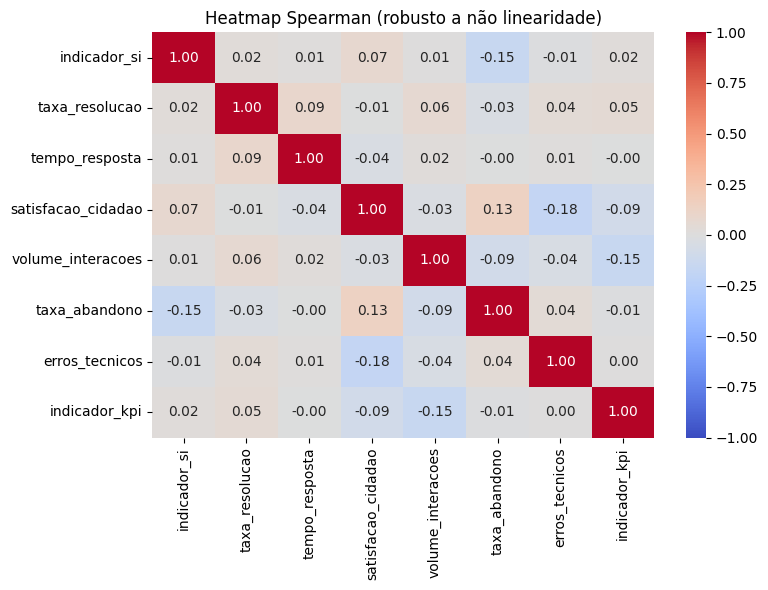

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Heatmap Spearman (robusto a não linearidade)")
plt.tight_layout()
plt.show()


In [30]:
#Diferença por canal
from scipy.stats import kruskal

# Tabela por canal
by_canal = df.groupby("canal_utilizado")[num_cols].agg(["count","mean","median","std"]).round(3)
by_canal


indicador_si                         taxa_resolucao          \
                       count    mean  median     std          count    mean   
canal_utilizado                                                               
Aplicacao_Movel           37  80.689  82.940  11.890             37  84.522   
Chatbot                   35  84.436  87.390  11.979             35  82.840   
Email                     32  83.581  82.885  11.105             32  81.731   
Portal                    30  78.529  77.455  12.289             30  83.065   
Presencial                38  81.443  84.080  13.777             38  82.891   
Telefone                  28  80.380  81.450  12.924             28  82.075   

                               tempo_resposta          ... taxa_abandono  \
                 median    std          count    mean  ...        median   
canal_utilizado                                        ...                 
Aplicacao_Movel  86.010  7.539             37  53.189  ...        11.240   
Chatbot          81.530  7.125             35  64.371  ...        13.950   
Email            79.530  8.217             32  57.594  ...        13.900   
Portal           83.645  8.104             30  64.633  ...        14.765   
Presencial       82.845  7.969             38  54.526  ...        11.310   
Telefone         80.845  8.012             28  59.679  ...        12.735   

                       erros_tecnicos                      indicador_kpi  \
                   std          count   mean median    std         count   
canal_utilizado                                                            
Aplicacao_Movel  7.086             37  6.568    6.0  4.266            37   
Chatbot          7.459             35  7.714    9.0  3.989            35   
Email            5.808             32  6.531    6.0  4.421            32   
Portal           5.711             30  7.300    7.0  4.203            30   
Presencial       6.167             38  7.579    7.5  3.753            38   
Telefone         7.116             28  6.357    5.0  4.621            28   

                                         
                   mean  median     std  
canal_utilizado                          
Aplicacao_Movel  76.323  76.620  13.655  
Chatbot          73.711  73.700  16.816  
Email            73.988  72.800  14.108  
Portal           73.772  72.480  14.130  
Presencial       77.543  78.045  11.598  
Telefone         75.076  75.070  15.495  

[6 rows x 32 columns]

In [31]:
tests = {}
for metric in ["indicador_kpi","tempo_resposta","satisfacao_cidadao","taxa_resolucao"]:
    groups = [g[metric].dropna().values for _, g in df.groupby("canal_utilizado")]
    H, p = kruskal(*groups)
    tests[metric] = {"H": H, "p_value": p}

pd.DataFrame(tests).T.round(6)


,H,p_value
indicador_kpi,2.225043,0.817211
tempo_resposta,2.934611,0.710066
satisfacao_cidadao,11.224759,0.047101
taxa_resolucao,3.018306,0.697163


In [32]:
#Tendencia Temporal
import matplotlib.pyplot as plt

monthly = df.groupby("mes")[["indicador_kpi","tempo_resposta","satisfacao_cidadao","taxa_resolucao"]].mean().round(2)
monthly


,indicador_kpi,tempo_resposta,satisfacao_cidadao,taxa_resolucao
mes,,,,
1,75.71,44.85,3.88,82.19
2,69.34,60.14,4.03,80.17
3,70.07,63.42,4.02,88.07
4,76.76,62.71,4.14,87.26
5,70.99,51.00,3.96,84.24
6,74.40,43.75,4.05,82.61
7,81.87,65.62,3.97,83.77
8,77.20,74.08,3.98,81.86
9,74.65,61.67,3.90,80.64


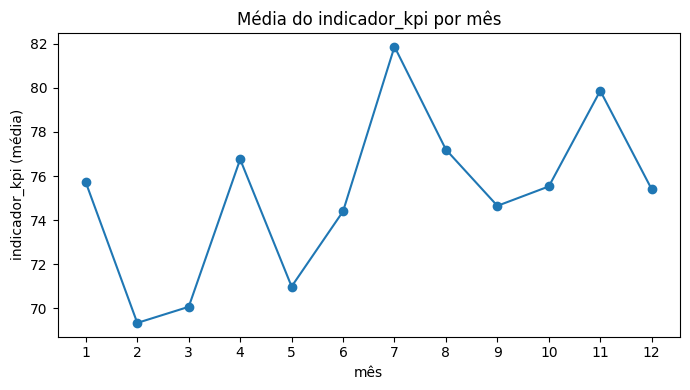

In [33]:
plt.figure(figsize=(7,4))
plt.plot(monthly.index, monthly["indicador_kpi"], marker="o")
plt.xticks(range(1,13))
plt.title("Média do indicador_kpi por mês")
plt.xlabel("mês")
plt.ylabel("indicador_kpi (média)")
plt.tight_layout()
plt.show()


In [34]:
#Diferença entre clusters
cluster_sizes = clustered["cluster"].value_counts().sort_index()
cluster_sizes

cluster
0    42
1    32
2    34
3    37
4    28
5    27
Name: count, dtype: int64

In [35]:
global_mean = clustered[num_cols].mean()
cluster_mean = clustered.groupby("cluster")[num_cols].mean()

delta = (cluster_mean - global_mean).round(2)
delta


,indicador_si,taxa_resolucao,tempo_resposta,satisfacao_cidadao,volume_interacoes,taxa_abandono,erros_tecnicos,indicador_kpi
cluster,,,,,,,,
0,-2.66,-3.55,-14.33,-0.53,-25.33,0.59,2.94,8.93
1,1.37,-5.21,-14.10,0.46,-26.62,5.85,1.25,-11.38
2,-11.44,4.86,17.01,-0.18,-35.27,3.97,-1.80,-1.44
3,8.70,7.96,12.30,0.08,-52.64,-3.46,1.99,4.00
4,1.75,-3.63,23.20,-0.04,172.98,-4.91,-2.18,-11.67
5,3.18,-1.57,-23.32,0.43,8.11,-3.02,-4.26,8.05


In [36]:
top_features = {}
for cl in delta.index:
    top = delta.loc[cl].abs().sort_values(ascending=False).head(3)
    top_features[cl] = list(top.index)

pd.DataFrame.from_dict(top_features, orient="index", columns=["Top1","Top2","Top3"])


,Top1,Top2,Top3
0,volume_interacoes,tempo_resposta,indicador_kpi
1,volume_interacoes,tempo_resposta,indicador_kpi
2,volume_interacoes,tempo_resposta,indicador_si
3,volume_interacoes,tempo_resposta,indicador_si
4,volume_interacoes,tempo_resposta,indicador_kpi
5,tempo_resposta,volume_interacoes,indicador_kpi


# Upgrade (alto impacto)

In [37]:
#Tabela Comparativa
import pandas as pd

metrics = ["indicador_kpi", "taxa_resolucao", "tempo_resposta", "satisfacao_cidadao", "taxa_abandono", "erros_tecnicos", "volume_interacoes"]

canal_summary = (
    df.groupby("canal_utilizado")[metrics]
      .agg(["count", "mean", "median", "std"])
      .round(3)
)

canal_summary


indicador_kpi                         taxa_resolucao          \
                        count    mean  median     std          count    mean   
canal_utilizado                                                                
Aplicacao_Movel            37  76.323  76.620  13.655             37  84.522   
Chatbot                    35  73.711  73.700  16.816             35  82.840   
Email                      32  73.988  72.800  14.108             32  81.731   
Portal                     30  73.772  72.480  14.130             30  83.065   
Presencial                 38  77.543  78.045  11.598             38  82.891   
Telefone                   28  75.076  75.070  15.495             28  82.075   

                               tempo_resposta          ... taxa_abandono  \
                 median    std          count    mean  ...        median   
canal_utilizado                                        ...                 
Aplicacao_Movel  86.010  7.539             37  53.189  ...        11.240   
Chatbot          81.530  7.125             35  64.371  ...        13.950   
Email            79.530  8.217             32  57.594  ...        13.900   
Portal           83.645  8.104             30  64.633  ...        14.765   
Presencial       82.845  7.969             38  54.526  ...        11.310   
Telefone         80.845  8.012             28  59.679  ...        12.735   

                       erros_tecnicos                      volume_interacoes  \
                   std          count   mean median    std             count   
canal_utilizado                                                                
Aplicacao_Movel  7.086             37  6.568    6.0  4.266                37   
Chatbot          7.459             35  7.714    9.0  3.989                35   
Email            5.808             32  6.531    6.0  4.421                32   
Portal           5.711             30  7.300    7.0  4.203                30   
Presencial       6.167             38  7.579    7.5  3.753                38   
Telefone         7.116             28  6.357    5.0  4.621                28   

                                          
                    mean median      std  
canal_utilizado                           
Aplicacao_Movel  248.054  236.0  134.729  
Chatbot          292.057  313.0  133.198  
Email            236.125  217.5  148.164  
Portal           264.867  295.0  156.063  
Presencial       247.368  251.5  139.800  
Telefone         214.857  187.0  141.940  

[6 rows x 28 columns]

In [38]:
#Teste Estático
from scipy.stats import kruskal

tests = {}
for metric in ["indicador_kpi", "taxa_resolucao", "tempo_resposta", "satisfacao_cidadao"]:
    groups = [g[metric].dropna().values for _, g in df.groupby("canal_utilizado")]
    H, p = kruskal(*groups)
    tests[metric] = {"H": H, "p_value": p}

pd.DataFrame(tests).round(6)


,indicador_kpi,taxa_resolucao,tempo_resposta,satisfacao_cidadao
H,2.225043,3.018306,2.934611,11.224759
p_value,0.817211,0.697163,0.710066,0.047101


# Data Quality Check

In [39]:
# 1) Missing values
missing = df.isnull().sum()
missing


id_registo                0
data_registo              0
unidade_organizacional    0
tipo_servico              0
indicador_si              0
taxa_resolucao            0
tempo_resposta            0
satisfacao_cidadao        0
volume_interacoes         0
canal_utilizado           0
taxa_abandono             0
erros_tecnicos            0
transparencia             0
feedback_cidadao          0
segmentacao_utilizador    0
area_tematica             0
indicador_kpi             0
ano                       0
mes                       0
dtype: int64

In [40]:
# 2) Duplicados
duplicates = df.duplicated().sum()
duplicates


np.int64(0)

In [41]:
# 3) Tipos de dados
df.dtypes


id_registo                         int64
data_registo              datetime64[ns]
unidade_organizacional            object
tipo_servico                      object
indicador_si                     float64
taxa_resolucao                   float64
tempo_resposta                     int64
satisfacao_cidadao               float64
volume_interacoes                  int64
canal_utilizado                   object
taxa_abandono                    float64
erros_tecnicos                     int64
transparencia                     object
feedback_cidadao                  object
segmentacao_utilizador            object
area_tematica                     object
indicador_kpi                    float64
ano                                int32
mes                                int32
dtype: object

In [42]:
# Verificação básica de limites plausíveis
checks = {
    "taxa_resolucao_out_of_range": df[(df["taxa_resolucao"] < 0) | (df["taxa_resolucao"] > 100)].shape[0],
    "satisfacao_out_of_range": df[(df["satisfacao_cidadao"] < 0) | (df["satisfacao_cidadao"] > 5)].shape[0],
    "taxa_abandono_out_of_range": df[(df["taxa_abandono"] < 0) | (df["taxa_abandono"] > 100)].shape[0]
}

checks


{'taxa_resolucao_out_of_range': 0,
 'satisfacao_out_of_range': 0,
 'taxa_abandono_out_of_range': 0}

# Validação adicional do Clustering


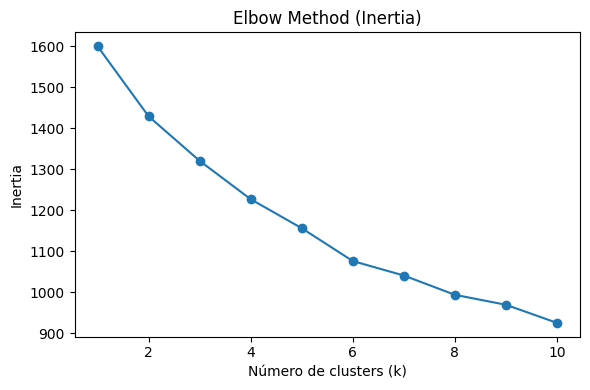

In [43]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

X = df[num_cols].dropna()
Xs = StandardScaler().fit_transform(X)

inertia = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    km.fit(Xs)
    inertia.append(km.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method (Inertia)")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inertia")
plt.tight_layout()
plt.show()


In [44]:
from sklearn.metrics import calinski_harabasz_score

ch_scores = {}

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels = km.fit_predict(Xs)
    score = calinski_harabasz_score(Xs, labels)
    ch_scores[k] = score

pd.Series(ch_scores)


2     23.669686
3     20.841776
4     19.855989
5     18.699686
6     18.877729
7     17.267806
8     16.718200
9     15.515342
10    15.378764
dtype: float64